# Stage 7 — Portfolio-Aware Stress-Scenario Recommendation

**Purpose.** Recommend a short, diverse list of *validated* stress scenarios from the Stage 6 library for a target portfolio, explain each choice from computed evidence, and report which stress patterns the library cannot supply. This stage generates no new scenarios and changes nothing in Stages 4–6.

**Inputs (audited).** `results/stage6/scenario_library.json` (schema `stage6.v2`, written by `stage_6.ipynb`): per scenario the executed action path, the complete five-day robustness path and factor-shock paths, family, cluster, deterministic rank, valid / implausible breach probabilities with sample sizes, screening result and a vulnerability summary for the default portfolio. Scenarios are replayed with the existing Stage 4 environment (`rlstress.rl.training.build_env`, deterministic conditional-mean residuals) to obtain each target portfolio's exact path drawdown. Logic lives in `rlstress.scenario_recommender` (tested in `tests/test_stage7_recommender.py`).

**Method.**
1. *Eligibility* (configurable, consistent with Stage 6): Stage 6 status `validated`, rank ≥ q = 0.01, screening P(valid) ≥ 80%, ≥ 100 reporting episodes, P(implausible) ≤ 5%, no missing evidence.
2. *Score* = Σ w·component, equal weights 0.25 fixed in advance (not tuned on any data): **relevance** (alignment of the cumulative factor shock with the portfolio's loss direction −w'B in sd units), **impact** (replayed drawdown, min-max across eligible), **plausibility** ($\ln(\rho/q)/\ln(1/q)$), **robustness** (lower 95% Wilson bound of P(valid)).
3. *Recommenders*: highest score; greedy diversity-aware (score − λ·max similarity to the already selected, similarity $=e^{-d/\tau}$ with the Stage 6 cumulative-path distance $d$ and $\tau$ = Stage 6 cluster cut); random eligible baseline.

**Data protocol.** Eligibility and the robustness score use Stage 6's reporting episodes (validation anchors, seeds 20000–20499). Stage 6 did not use them for selection, but Stage 7 does, so any shortlist metric built on them is **in-sample** for Stage 7. An **independent evaluation** therefore replays every eligible scenario's complete five-day path on 500 fresh, common validation episodes (seeds 30000–30499) that no Stage 5–7 selection step has used. These results are reported separately and do not change the ranking. Portfolio history uses the training split only. The 2024–2025 test split is not used, and nothing is tuned.

## 1. Configuration and reproducibility

In [1]:
import dataclasses
import hashlib
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from rlstress.config import PROJECT_ROOT, load_config, resolve_path
from rlstress.data.storage import read_frame
from rlstress.rl.evaluation import evaluate_policy
from rlstress.rl.training import build_env
from rlstress.scenario_library import FACTOR_ORDER, holding_contributions, robustness_summary
from rlstress.scenario_recommender import (COMPONENTS, TARGET_FAMILIES, RecommenderConfig, coverage_gaps, eligibility, exact_weight_shift, explain,
                                           library_fingerprint, load_library, portfolio_profile, scenario_features, score, select_diverse, select_random,
                                           select_top, shortlist_fresh_metrics, shortlist_metrics)
from rlstress.search import OpenLoopPolicy, evaluate_path
from rlstress.shocks import ShockModel

%matplotlib inline
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3dc", "grid.linewidth": 0.8})

CFG = load_config()
SIM = CFG.simulation
H = SIM.horizon_days
SEED = SIM.seed
LIBRARY_PATH = PROJECT_ROOT / "results" / "stage6" / "scenario_library.json"
OUT_DIR = PROJECT_ROOT / "results" / "stage7"
OUT_PATH = OUT_DIR / "recommendations.json"
OVERWRITE = False
RCFG = RecommenderConfig(q=SIM.min_plausibility, top_k=5)          # equal weights, Stage 6 thresholds, lambda = 0.5
RANDOM_SEEDS = range(SEED, SEED + 1000)                              # random-baseline repetitions (selection RNG only, no episodes)
FRESH_SEEDS = range(CFG.training.eval_seed_sets[1], CFG.training.eval_seed_sets[1] + 500)   # independent evaluation: 30000-30499, validation anchors
PREVIOUS_OUTPUT = PROJECT_ROOT / "backups" / "stage7_recommendations_v1_2026-10-25.json"     # v1 run: ranking must be reproduced unchanged
# Every episode-seed range used upstream (from the Stage 5 and Stage 6 notebook settings), for the independence check.
UPSTREAM_SEEDS = {
    "Stage 5/6 screening (validation)": range(10_000, 10_200),
    "Stage 5/6 reporting = Stage 7 eligibility and robustness score (validation)": range(20_000, 20_500),
    "Stage 5/6 Q-learning, Double and 5-step training, seeds 43-45 x 20,000 episodes (train)": range(43, 45 + 20_000),
    "Stage 5/6 discrete Monte Carlo draws (train)": range(50_000, 50_010),
    "Stage 5 DP model data (train)": range(60_000, 80_000),
    "Stage 6 Q-learning harvest (train)": range(70_000, 70_200),
}

def tree_hash(paths):
    h = hashlib.sha256()
    for p in sorted(paths):
        h.update(str(p.relative_to(PROJECT_ROOT)).encode()); h.update(p.read_bytes())
    return h.hexdigest()
PROTECTED = {name: sorted(p for p in (PROJECT_ROOT / "results" / name).rglob("*") if p.is_file())
             for name in ("stage4", "stage5", "stage6") if (PROJECT_ROOT / "results" / name).exists()}
HASH_BEFORE = {name: tree_hash(paths) for name, paths in PROTECTED.items()}
print("Recommender config:", RCFG)
print("Protected result trees hashed:", {k: len(v) for k, v in PROTECTED.items()})

Recommender config: RecommenderConfig(q=0.01, min_screening_p_valid=0.8, min_reporting_episodes=100, max_p_implausible=0.05, require_validated=True, weights={'relevance': 0.25, 'impact': 0.25, 'plausibility': 0.25, 'robustness': 0.25}, diversity_penalty=0.5, similarity_scale=0.671, top_k=5)
Protected result trees hashed: {'stage4': 4, 'stage5': 337, 'stage6': 1}


## 2. Load and validate the Stage 6 library

In [2]:
library = load_library(LIBRARY_PATH)                 # raises if missing, malformed, empty or wrong factor order
meta = library["metadata"]
LIB_SHA = library_fingerprint(LIBRARY_PATH)
assert meta["selection_rule"].get("test_split_used") is False, "Stage 6 library reports test-split use"
assert meta["run_mode"] == "full", "library was not produced by a full Stage 6 run"
assert meta["plausibility_threshold_q"] == RCFG.q
SCREEN_SEEDS = range(meta["selection_rule"]["screening_seeds"][0], meta["selection_rule"]["screening_seeds"][1] + 1)
REPORT_SEEDS = range(meta["selection_rule"]["reporting_seeds"][0], meta["selection_rule"]["reporting_seeds"][1] + 1)
assert SCREEN_SEEDS == range(10_000, 10_200) and REPORT_SEEDS == range(20_000, 20_500), "library seeds differ from the seed register"
lib_by_id = {s["scenario_id"]: s for s in library["scenarios"]}
status = pd.Series([s["status"] for s in library["scenarios"]]).value_counts()
print(f"Loaded {LIBRARY_PATH.relative_to(PROJECT_ROOT)} (sha256 {LIB_SHA[:12]}…, generated {meta['generated_utc']}): {len(library['scenarios'])} scenarios")
display(status.to_frame("scenarios"))
display(pd.DataFrame([meta["candidate_counts"]]).T.rename(columns={0: "count"}).style.set_caption("Stage 6 candidate counts (provenance)"))

Loaded results/stage6/scenario_library.json (sha256 47bb6c5d3049…, generated 2026-10-24T20:23:12.111586+00:00): 16 scenarios


,scenarios
validated,8
exploratory,8


,count
raw candidates,8961
unique action paths,7763
unique executed paths,7581
"deterministic valid, unique executed (excl. reference)",565
near-duplicate groups (1-step cut),290
scenario clusters (2-step cut),16


## 3. Portfolio risk profile
Default = the project portfolio. Three *hypothetical* alternatives over the same eight holdings (the shock model is fitted on these stocks) are used only to test how the recommendations respond to the portfolio; they are not investment proposals.

In [3]:
source = read_frame(resolve_path(CFG.risk.returns_path, PROJECT_ROOT))
model = ShockModel.from_dict(json.loads((PROJECT_ROOT / SIM.output_dir / "shock_model.json").read_text()))
train_start, train_end = CFG.data.splits.as_dict()["train"]
tickers = list(CFG.portfolio.tickers)
train_returns = source.loc[train_start:train_end, [f"{t}_return" for t in tickers]].rename(columns=lambda c: c.removesuffix("_return"))
assert train_returns.index.max() <= pd.Timestamp(train_end)
sectors = {a.alias: a.sector for a in CFG.data.enabled_assets("stock")}
dd_limit = next(l.threshold for l in CFG.risk.limits if l.metric == "max_drawdown" and l.horizon_days == H)
base_w = np.array(CFG.portfolio.weights, dtype=float)
PORTFOLIOS = {
    "default (equal weight)": base_w,
    "hypothetical: technology-heavy": np.array([0.25, 0.25, 0.25, 0.05, 0.05, 0.05, 0.05, 0.05]),
    "hypothetical: financials and energy-heavy": np.array([0.05, 0.05, 0.05, 0.30, 0.30, 0.05, 0.05, 0.15]),
    "hypothetical: defensive": np.array([0.05, 0.10, 0.05, 0.10, 0.10, 0.30, 0.25, 0.05]),
}
profiles = {name: portfolio_profile(name, tickers, w, CFG.portfolio.initial_capital, model.raw_loadings, model.factor_sd, sectors,
                                    train_returns, dd_limit) for name, w in PORTFOLIOS.items()}
names = [f.removesuffix("_return") for f in FACTOR_ORDER]
display(pd.DataFrame([{"portfolio": n, **{f"w'B {k}": v for k, v in p.factor_loadings.items()}, "annual vol (train)": p.annual_volatility,
                       "max drawdown (train)": p.max_drawdown, "largest sector": max(p.sector_weights, key=p.sector_weights.get)} for n, p in profiles.items()])
        .style.hide(axis="index").format({**{f"w'B {k}": "{:.3f}" for k in names}, "annual vol (train)": "{:.1%}", "max drawdown (train)": "{:.1%}"}))
for v in profiles["default (equal weight)"].vulnerabilities:
    print("-", v)

portfolio,w'B SPY,w'B QQQ,w'B XLF,w'B XLE,annual vol (train),max drawdown (train),largest sector
default (equal weight),0.424,0.362,0.125,0.090,20.1%,-30.6%,Technology
hypothetical: technology-heavy,-0.056,1.059,0.064,0.040,24.7%,-33.1%,Technology
hypothetical: financials and energy-heavy,0.178,0.115,0.413,0.265,22.1%,-40.5%,Financials
hypothetical: defensive,1.066,-0.126,-0.036,-0.004,17.1%,-25.5%,Healthcare


- largest factor sensitivity: SPY (w'B = 0.42)
- largest sector weight: Technology (25%)
- training-period max drawdown -30.6% vs 10% 5-day drawdown limit


## 4. Scenario features and portfolio impact (replayed in the Stage 4 environment)

In [4]:
features = eligibility(scenario_features(library, model.factor_sd, H), RCFG)
envs, impacts, holdings = {}, {}, {}
t0 = time.perf_counter()
for name, w in PORTFOLIOS.items():
    pcfg = dataclasses.replace(CFG, portfolio=dataclasses.replace(CFG.portfolio, weights=tuple(float(x) for x in w)),
                               simulation=dataclasses.replace(SIM, residual_mode="mean"))
    env = build_env(pcfg, source, model, SIM.min_plausibility, "train")
    anchor = env.market_states.index[len(env.market_states) // 2]
    impacts[name], holdings[name] = {}, {}
    for _, r in features.iterrows():
        rec = evaluate_path(env, np.asarray(r["padded_action_path"]), anchor, SEED)
        impacts[name][r["scenario_id"]] = float(rec["drawdown"])
        hc = holding_contributions(np.array(rec["stock_returns"]), w, CFG.portfolio.initial_capital, tickers)
        holdings[name][r["scenario_id"]] = dict(zip(hc["ticker"], hc["pnl"]))
replay_runtime = time.perf_counter() - t0
default = "default (equal weight)"
consistency = max(abs(impacts[default][r["scenario_id"]] - r["deterministic_drawdown"]) for _, r in features.iterrows())
print(f"Replayed {len(features)} scenarios x {len(PORTFOLIOS)} portfolios in {replay_runtime:.1f}s; "
      f"default-portfolio drawdowns match the Stage 6 library within {consistency:.1e}")
assert consistency < 1e-9, "replay does not reproduce the Stage 6 deterministic drawdowns"
display(features[["scenario_id", "status", "family", "cluster", "executed_days", "rank", "p_valid", "p_valid_ci_low", "p_implausible",
                  "reporting_episodes", "screening_p_valid", "eligible", "ineligible_reason"]]
        .style.hide(axis="index").format({"rank": "{:.4f}", "p_valid": "{:.1%}", "p_valid_ci_low": "{:.1%}", "p_implausible": "{:.1%}", "screening_p_valid": "{:.1%}"}, na_rep="—"))
print(f"Eligible: {int(features['eligible'].sum())} of {len(features)}")

Replayed 16 scenarios x 4 portfolios in 0.4s; default-portfolio drawdowns match the Stage 6 library within 0.0e+00


scenario_id,status,family,cluster,executed_days,rank,p_valid,p_valid_ci_low,p_implausible,reporting_episodes,screening_p_valid,eligible,ineligible_reason
S6-bf3237d7,validated,broad-market,2,5,0.0506,91.0%,88.2%,0.0%,500.000000,91.0%,True,
S6-57e21a76,validated,broad-market,13,5,0.0501,95.0%,92.7%,0.0%,500.000000,98.0%,True,
S6-0b517d5c,validated,broad-market,10,5,0.0444,98.0%,96.4%,0.0%,500.000000,98.5%,True,
S6-3b5f9089,validated,broad-market,9,4,0.0398,86.0%,82.7%,0.0%,500.000000,88.0%,True,
S6-b13030ae,validated,broad-market,4,5,0.0330,88.2%,85.1%,0.0%,500.000000,92.0%,True,
S6-cb7bea96,validated,broad-market,12,4,0.0205,100.0%,99.2%,0.0%,500.000000,100.0%,True,
S6-b0972d80,validated,sector-led (financials and energy jointly),5,5,0.0131,93.0%,90.4%,0.0%,500.000000,95.0%,True,
S6-5d0455b6,validated,broad-market,11,3,0.0119,100.0%,99.2%,0.0%,500.000000,100.0%,True,
S6-ae72a2db,exploratory,broad-market,15,5,0.0859,68.6%,64.4%,0.0%,500.000000,64.0%,False,not validated in Stage 6; screening P(valid) 64.0% < 80%
S6-fc5a7b85,exploratory,broad-market,16,5,0.0808,74.6%,70.6%,0.0%,500.000000,77.5%,False,not validated in Stage 6; screening P(valid) 77.5% < 80%


Eligible: 8 of 16


## 5. Baseline scoring and ranking (highest individual score)

In [5]:
scored = {name: score(features, profiles[name], impacts[name], RCFG) for name in PORTFOLIOS}
S = scored[default]
top_ids = select_top(S, RCFG.top_k)
display(S[S["eligible"]].sort_values(["score", "scenario_id"], ascending=[False, True])
        [["scenario_id", "family", "cluster", "portfolio_drawdown", *COMPONENTS, "score"]]
        .style.hide(axis="index").format({"portfolio_drawdown": "{:.2%}", **{c: "{:.3f}" for c in COMPONENTS}, "score": "{:.3f}"})
        .set_caption(f"Eligible scenarios scored for the default portfolio (weights {RCFG.weights})"))
print("Highest-score shortlist:", top_ids)

scenario_id,family,cluster,portfolio_drawdown,relevance,impact,plausibility,robustness,score
S6-cb7bea96,broad-market,12,13.44%,0.994,1.000,0.156,0.992,0.785
S6-0b517d5c,broad-market,10,12.58%,0.972,0.623,0.324,0.964,0.721
S6-57e21a76,broad-market,13,11.95%,0.987,0.347,0.350,0.927,0.653
S6-b0972d80,sector-led (financials and energy jointly),5,12.35%,0.916,0.523,0.058,0.904,0.600
S6-5d0455b6,broad-market,11,12.03%,0.987,0.383,0.038,0.992,0.600
S6-bf3237d7,broad-market,2,11.38%,0.997,0.098,0.352,0.882,0.582
S6-b13030ae,broad-market,4,11.40%,0.997,0.107,0.259,0.851,0.554
S6-3b5f9089,broad-market,9,11.15%,0.956,0.000,0.300,0.827,0.521


Highest-score shortlist: ['S6-cb7bea96', 'S6-0b517d5c', 'S6-57e21a76', 'S6-b0972d80', 'S6-5d0455b6']


## 6. Diversity-aware ranking

In [6]:
div = select_diverse(S, RCFG.top_k, RCFG)
div_ids = [d["scenario_id"] for d in div]
display(pd.DataFrame(div).style.hide(axis="index").format({"score": "{:.3f}", "adjusted_score": "{:.3f}", "max_similarity_to_selected": "{:.3f}"})
        .set_caption(f"Greedy selection: score - {RCFG.diversity_penalty} x max similarity (tau = {RCFG.similarity_scale})"))
print("Diversity-aware shortlist:", div_ids)

scenario_id,score,adjusted_score,max_similarity_to_selected
S6-cb7bea96,0.785,0.785,0.000
S6-0b517d5c,0.721,0.574,0.294
S6-b0972d80,0.600,0.506,0.188
S6-b13030ae,0.554,0.501,0.105
S6-57e21a76,0.653,0.459,0.387


Diversity-aware shortlist: ['S6-cb7bea96', 'S6-0b517d5c', 'S6-b0972d80', 'S6-b13030ae', 'S6-57e21a76']


## 7. Comparison with baselines and stability
Same eligibility and shortlist size for all three. The random baseline is summarised over 1,000 seeds. **The P(valid) columns of this table are in-sample** (Stage 6 reporting episodes, also used for eligibility and the robustness score). Section 7b gives the independent evaluation. Stability: Jaccard overlap of the diversity-aware shortlist under (a) each weight moved by exactly ±0.05, with ∓0.05/3 spread equally across the other three (tested weights shown), (b) the alternative portfolios, (c) different diversity penalties.

In [7]:
t0 = time.perf_counter()
rows = [{"recommender": "highest score", **shortlist_metrics(S, top_ids, RCFG)},
        {"recommender": "diversity-aware", **shortlist_metrics(S, div_ids, RCFG)}]
rand = pd.DataFrame([shortlist_metrics(S, select_random(S, RCFG.top_k, s), RCFG) for s in RANDOM_SEEDS])
rows.append({"recommender": f"random (mean of {len(RANDOM_SEEDS)} seeds)", **rand.mean(numeric_only=True).to_dict()})
comparison = pd.DataFrame(rows).set_index("recommender")
display(comparison.style.format("{:.3f}", na_rep="—").set_caption("Shortlist quality, diversity and coverage (default portfolio); P(valid) columns IN-SAMPLE (reporting seeds 20000-20499)"))

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0
stab = []
for comp in COMPONENTS:
    for delta in (-0.05, 0.05):
        w = exact_weight_shift(RCFG.weights, comp, delta)              # comp moves exactly delta; the others -delta/3 each
        cfg = dataclasses.replace(RCFG, weights=w)
        ids = [d["scenario_id"] for d in select_diverse(score(features, profiles[default], impacts[default], cfg), RCFG.top_k, cfg)]
        stab.append({"perturbation": f"weight {comp} {delta:+.2f}", **{f"w {c}": w[c] for c in COMPONENTS},
                     "jaccard vs default": jaccard(ids, div_ids), "same order": ids == div_ids})
for name in PORTFOLIOS:
    if name != default:
        ids = [d["scenario_id"] for d in select_diverse(scored[name], RCFG.top_k, RCFG)]
        stab.append({"perturbation": f"portfolio: {name}", "jaccard vs default": jaccard(ids, div_ids), "same order": ids == div_ids})
for lam in (0.0, 0.25, 1.0, 2.0):
    cfg = dataclasses.replace(RCFG, diversity_penalty=lam)
    ids = [d["scenario_id"] for d in select_diverse(S, RCFG.top_k, cfg)]
    stab.append({"perturbation": f"lambda = {lam}", "jaccard vs default": jaccard(ids, div_ids), "same order": ids == div_ids, **{k: v for k, v in shortlist_metrics(S, ids, cfg).items() if k in ("distinct clusters", "mean score", "mean pairwise similarity")}})
stability = pd.DataFrame(stab)
eval_runtime = time.perf_counter() - t0
weight_rows = stability[stability["perturbation"].str.startswith("weight")]
display(stability.style.hide(axis="index").format({**{f"w {c}": "{:.4f}" for c in COMPONENTS}, "jaccard vs default": "{:.2f}", "mean score": "{:.3f}", "mean pairwise similarity": "{:.3f}"}, na_rep="—"))
print(f"Evaluation runtime {eval_runtime:.1f}s; reproducibility: re-running the selections gives identical lists:",
      select_top(S, RCFG.top_k) == top_ids and [d["scenario_id"] for d in select_diverse(S, RCFG.top_k, RCFG)] == div_ids)

,size,eligibility compliance,mean score,mean relevance,mean portfolio drawdown,mean P(valid),min P(valid),mean rank,distinct clusters,distinct families,min pairwise distance,mean pairwise similarity
recommender,,,,,,,,,,,,
highest score,5.000,1.000,0.672,0.971,0.125,0.972,0.930,0.028,5.000,2.000,0.520,0.268
diversity-aware,5.000,1.000,0.663,0.973,0.123,0.948,0.882,0.032,5.000,2.000,0.636,0.187
random (mean of 1000 seeds),5.000,1.000,0.626,0.976,0.120,0.939,0.872,0.033,5.000,1.631,0.558,0.225


perturbation,w relevance,w impact,w plausibility,w robustness,jaccard vs default,same order,mean score,distinct clusters,mean pairwise similarity
weight relevance -0.05,0.2000,0.2667,0.2667,0.2667,1.00,True,—,—,—
weight relevance +0.05,0.3000,0.2333,0.2333,0.2333,1.00,False,—,—,—
weight impact -0.05,0.2667,0.2000,0.2667,0.2667,1.00,False,—,—,—
weight impact +0.05,0.2333,0.3000,0.2333,0.2333,1.00,True,—,—,—
weight plausibility -0.05,0.2667,0.2667,0.2000,0.2667,1.00,True,—,—,—
weight plausibility +0.05,0.2333,0.2333,0.3000,0.2333,1.00,False,—,—,—
weight robustness -0.05,0.2667,0.2667,0.2667,0.2000,1.00,True,—,—,—
weight robustness +0.05,0.2333,0.2333,0.2333,0.3000,1.00,True,—,—,—
portfolio: hypothetical: technology-heavy,—,—,—,—,0.67,False,—,—,—
portfolio: hypothetical: financials and energy-heavy,—,—,—,—,0.67,False,—,—,—


Evaluation runtime 0.5s; reproducibility: re-running the selections gives identical lists: True


## 7b. Independent evaluation on fresh validation episodes (ranking unchanged)
Every eligible scenario's complete five-day `robust_action_path` is replayed open-loop in the Stage 6 evaluation environment (sampled residuals, validation anchors) on the same 500 fresh seeds 30000–30499. The seeds are checked first against every seed range used upstream. As a pipeline check, one scenario is also re-run on the Stage 6 reporting seeds and must reproduce the library values exactly. The shortlists above are **not** re-ranked. The tables put the in-sample metrics (reporting episodes) next to the independent ones for the three recommenders, with the random baseline averaged over its 1,000 selections.

In [8]:
overlaps = {name: sorted(set(FRESH_SEEDS) & set(r))[:3] for name, r in UPSTREAM_SEEDS.items()}
seed_register = pd.DataFrame([{"use": n, "seeds": f"{r.start}-{r.stop - 1}", "overlap with fresh seeds": len(set(FRESH_SEEDS) & set(r))} for n, r in UPSTREAM_SEEDS.items()]
                             + [{"use": "Stage 7 independent evaluation (validation)", "seeds": f"{FRESH_SEEDS.start}-{FRESH_SEEDS.stop - 1}", "overlap with fresh seeds": None}])
display(seed_register.style.hide(axis="index").set_caption("Episode-seed register (Stage 7 ranking uses library values and deterministic replay only, no episodes)"))
seeds_independent = not any(overlaps.values())
assert seeds_independent, f"fresh seeds overlap upstream use: {overlaps}"

t0 = time.perf_counter()
eval_env = build_env(CFG, source, model, SIM.min_plausibility, "validation")      # as Stage 6: sampled residuals, validation anchors
assert SIM.residual_mode == "sample"
OBS = {n: i for i, n in enumerate(eval_env.observation_names)}
elig_ids = sorted(S.loc[S["eligible"], "scenario_id"])
policy_for = lambda sid: OpenLoopPolicy(np.asarray(lib_by_id[sid]["robust_action_path"], dtype=float), OBS, sid)

# Pipeline check: the first eligible scenario on the Stage 6 reporting seeds must reproduce the stored library values.
chk = robustness_summary(evaluate_policy(eval_env, policy_for(elig_ids[0]), REPORT_SEEDS))
lib0 = lib_by_id[elig_ids[0]]
reporting_reproduced = (chk["episodes"] == lib0["reporting_episodes"] and np.isclose(chk["p_valid"], lib0["p_valid"])
                        and np.isclose(chk["p_implausible"], lib0["p_implausible"]) and np.isclose(chk["mean_drawdown_at_breach"], lib0["mean_drawdown_at_breach"]))
print(f"Pipeline check on {elig_ids[0]} (reporting seeds): P(valid) {chk['p_valid']:.3f} vs library {lib0['p_valid']:.3f}; reproduced: {reporting_reproduced}")

fresh_records = {sid: evaluate_policy(eval_env, policy_for(sid), FRESH_SEEDS) for sid in elig_ids}
fresh_runtime = time.perf_counter() - t0
fresh_rows = []
for sid, recs_ in fresh_records.items():
    s_ = robustness_summary(recs_)
    fresh_rows.append({"scenario_id": sid, "episodes": s_["episodes"], "p_valid": s_["p_valid"], "p_valid_ci_low": s_["p_valid_ci95"][0],
                       "p_valid_ci_high": s_["p_valid_ci95"][1], "p_any_breach": s_["p_any_breach"], "p_implausible": s_["p_implausible"],
                       "median_valid_rank": s_["median_valid_rank"], "mean_drawdown_at_breach": s_["mean_drawdown_at_breach"],
                       "mean_breach_day": s_["mean_breach_day"], "first_seed": recs_[0].episode_seed, "last_seed": recs_[-1].episode_seed})
fresh = pd.DataFrame(fresh_rows).set_index("scenario_id")
fresh_seed_lists_ok = all([r.episode_seed for r in recs_] == list(FRESH_SEEDS) for recs_ in fresh_records.values())
in_sample = pd.DataFrame([{"scenario_id": sid, "episodes": lib_by_id[sid]["reporting_episodes"], "p_valid": lib_by_id[sid]["p_valid"],
                           "p_implausible": lib_by_id[sid]["p_implausible"], "mean_drawdown_at_breach": lib_by_id[sid]["mean_drawdown_at_breach"]}
                          for sid in elig_ids]).set_index("scenario_id")

per_scenario = pd.DataFrame({"score rank": S.set_index("scenario_id").loc[elig_ids, "score"].rank(ascending=False, method="first").astype(int),
                             "in-sample P(valid)": in_sample["p_valid"], "fresh P(valid)": fresh["p_valid"],
                             "fresh 95% CI low": fresh["p_valid_ci_low"], "fresh 95% CI high": fresh["p_valid_ci_high"],
                             "in-sample P(implausible)": in_sample["p_implausible"], "fresh P(implausible)": fresh["p_implausible"],
                             "in-sample drawdown at breach": in_sample["mean_drawdown_at_breach"], "fresh drawdown at breach": fresh["mean_drawdown_at_breach"],
                             "fresh episodes": fresh["episodes"]}).sort_values("score rank")
display(per_scenario.style.format({c: "{:.1%}" for c in per_scenario.columns if c not in ("score rank", "fresh episodes")})
        .set_caption(f"Eligible scenarios: in-sample (seeds {REPORT_SEEDS.start}-{REPORT_SEEDS.stop - 1}) vs independent (seeds {FRESH_SEEDS.start}-{FRESH_SEEDS.stop - 1})"))

def both(ids):
    out = {}
    for label, table in (("in-sample", in_sample), ("independent", fresh)):
        m = shortlist_fresh_metrics(table, ids)
        out[label] = {k.removeprefix("fresh "): v for k, v in m.items() if k != "size"}
    return out
rand_eval = [both(select_random(S, RCFG.top_k, s)) for s in RANDOM_SEEDS]
eval_rows = []
for name, res in (("highest score", both(top_ids)), ("diversity-aware", both(div_ids))):
    for label in ("in-sample", "independent"):
        eval_rows.append({"recommender": name, "evaluation": label, **res[label]})
for label in ("in-sample", "independent"):
    eval_rows.append({"recommender": f"random (mean of {len(RANDOM_SEEDS)} seeds)", "evaluation": label,
                      **pd.DataFrame([r[label] for r in rand_eval]).mean().to_dict()})
comparison_eval = pd.DataFrame(eval_rows).set_index(["recommender", "evaluation"])
display(comparison_eval.style.format("{:.1%}").set_caption(
    f"Shortlist robustness: in-sample = Stage 6 reporting seeds (used by Stage 7); independent = {len(FRESH_SEEDS)} fresh seeds {FRESH_SEEDS.start}-{FRESH_SEEDS.stop - 1}"))
print(f"Independent evaluation: {len(elig_ids)} eligible scenarios x {len(FRESH_SEEDS)} episodes in {fresh_runtime:.1f}s; "
      f"identical seed list for every scenario: {fresh_seed_lists_ok}; ranking unchanged by construction (shortlists fixed above)")


use,seeds,overlap with fresh seeds
Stage 5/6 screening (validation),10000-10199,0.000000
Stage 5/6 reporting = Stage 7 eligibility and robustness score (validation),20000-20499,0.000000
"Stage 5/6 Q-learning, Double and 5-step training, seeds 43-45 x 20,000 episodes (train)",43-20044,0.000000
Stage 5/6 discrete Monte Carlo draws (train),50000-50009,0.000000
Stage 5 DP model data (train),60000-79999,0.000000
Stage 6 Q-learning harvest (train),70000-70199,0.000000
Stage 7 independent evaluation (validation),30000-30499,nan


Pipeline check on S6-0b517d5c (reporting seeds): P(valid) 0.980 vs library 0.980; reproduced: True


,score rank,in-sample P(valid),fresh P(valid),fresh 95% CI low,fresh 95% CI high,in-sample P(implausible),fresh P(implausible),in-sample drawdown at breach,fresh drawdown at breach,fresh episodes
scenario_id,,,,,,,,,,
S6-cb7bea96,1,100.0%,100.0%,99.2%,100.0%,0.0%,0.0%,11.8%,11.9%,500
S6-0b517d5c,2,98.0%,98.8%,97.4%,99.4%,0.0%,0.0%,12.1%,12.1%,500
S6-57e21a76,3,95.0%,96.4%,94.4%,97.7%,0.0%,0.0%,11.1%,11.1%,500
S6-b0972d80,4,93.0%,96.0%,93.9%,97.4%,0.0%,0.0%,12.0%,11.9%,500
S6-5d0455b6,5,100.0%,100.0%,99.2%,100.0%,0.0%,0.0%,11.9%,11.9%,500
S6-bf3237d7,6,91.0%,92.0%,89.3%,94.1%,0.0%,0.0%,11.6%,11.7%,500
S6-b13030ae,7,88.2%,91.4%,88.6%,93.6%,0.0%,0.0%,11.8%,11.8%,500
S6-3b5f9089,8,86.0%,89.2%,86.2%,91.6%,0.0%,0.0%,10.9%,11.0%,500


Independent evaluation: 8 eligible scenarios x 500 episodes in 30.8s; identical seed list for every scenario: True; ranking unchanged by construction (shortlists fixed above)


## 8. Recommendations with explanations, and coverage gaps

In [9]:
rows_by_id = S.set_index("scenario_id", drop=False)
recs = []
for i, d in enumerate(div, 1):
    row = rows_by_id.loc[d["scenario_id"]]
    prev = [rows_by_id.loc[x["scenario_id"]] for x in div[: i - 1]]
    recs.append({"rank": i, "scenario_id": d["scenario_id"], "score": d["score"], "adjusted_score": d["adjusted_score"],
                 "discovery_methods": row["discovery_methods"], "family": row["family"], "cluster": row["cluster"],
                 "executed_days": int(lib_by_id[d["scenario_id"]]["executed_days"]),
                 "factor_shock_path": [[float(x) for x in day] for day in lib_by_id[d["scenario_id"]]["factor_shock_path"]],
                 "robust_action_path": [[float(x) for x in day] for day in lib_by_id[d["scenario_id"]]["robust_action_path"]],
                 "robust_factor_shock_path": [[float(x) for x in day] for day in lib_by_id[d["scenario_id"]]["robust_factor_shock_path"]],
                 "provenance": {"library_sha256": LIB_SHA, "representative_candidate_id": lib_by_id[d["scenario_id"]]["representative_candidate_id"],
                                "discovery_methods": lib_by_id[d["scenario_id"]]["discovery_methods"], "selection_reason": lib_by_id[d["scenario_id"]]["selection_reason"],
                                "stage6": lib_by_id[d["scenario_id"]]["provenance"]},
                 "portfolio_drawdown": row["portfolio_drawdown"], "components": {c: float(row[c]) for c in COMPONENTS},
                 "evidence_in_sample": {"rank": row["rank"], "p_valid": row["p_valid"], "p_valid_ci95": [row["p_valid_ci_low"], row["p_valid_ci_high"]],
                                        "p_implausible": row["p_implausible"], "mean_drawdown_at_breach": lib_by_id[d["scenario_id"]]["mean_drawdown_at_breach"],
                                        "episodes": int(row["reporting_episodes"]), "seeds": [REPORT_SEEDS.start, REPORT_SEEDS.stop - 1],
                                        "note": "Stage 6 reporting episodes; used by Stage 7 for eligibility and the robustness score (in-sample)"},
                 "evidence_independent": {**{k: fresh.loc[d["scenario_id"], k] for k in ("p_valid", "p_implausible", "p_any_breach", "median_valid_rank",
                                                                                         "mean_drawdown_at_breach", "mean_breach_day")},
                                           "p_valid_ci95": [fresh.loc[d["scenario_id"], "p_valid_ci_low"], fresh.loc[d["scenario_id"], "p_valid_ci_high"]],
                                           "episodes": int(fresh.loc[d["scenario_id"], "episodes"]), "seeds": [FRESH_SEEDS.start, FRESH_SEEDS.stop - 1],
                                           "note": "fresh validation episodes, not used for any selection or ranking"},
                 "explanation": explain(row, profiles[default], prev, RCFG, holdings[default][d["scenario_id"]])})
for r in recs:
    print(f"#{r['rank']} {r['scenario_id']} (score {r['score']:.3f}, adjusted {r['adjusted_score']:.3f}; {r['discovery_methods']})\n   {r['explanation']}\n"
          f"   Independent check ({r['evidence_independent']['episodes']} fresh episodes): P(valid) {r['evidence_independent']['p_valid']:.1%} "
          f"[{r['evidence_independent']['p_valid_ci95'][0]:.1%}, {r['evidence_independent']['p_valid_ci95'][1]:.1%}], "
          f"P(implausible) {r['evidence_independent']['p_implausible']:.1%}\n")
gaps = coverage_gaps(S)
display(gaps.style.hide(axis="index").set_caption("Target scenario families: present in the library / among eligible scenarios"))
missing = list(gaps.loc[~gaps["eligible"], "family"])
print("Missing families:", missing, "— the Stage 5/6 nine-action space ties SPY to QQQ and XLF to XLE, so technology-, financial- and "
      "energy-only paths cannot be generated by the discrete methods; they are reported as gaps, not filled.")

#1 S6-cb7bea96 (score 0.785, adjusted 0.785; Monte Carlo (discrete))
   broad-market scenario over 4 day(s); largest cumulative shock on SPY (-12.6 model sd; cumulative factor returns SPY -12.7%, QQQ -15.8%, XLF -9.8%, XLE -13.3%). Relevance 0.99: alignment with this portfolio's loss direction (largest sensitivity SPY). Impact: replayed path drawdown 13.44% for 'default (equal weight)' (limit 10%). Largest holding losses: NVDA -2,869, AAPL -2,223, MSFT -2,133. Evidence: rank 0.0205 (q = 0.01); P(valid) 100.0% [99.2%, 100.0%] on 500 reporting episodes; P(implausible) 0.0%; screening P(valid) 100.0% on 200. Limitations: fixed five-day path replayed in the Stage 4 model (i.i.d. daily shocks, tails lighter than history); robustness from Stage 6 reporting episodes (validation-period residual draws, separate from the screening episodes Stage 6 used for selection); not a test-period result.
   Independent check (500 fresh episodes): P(valid) 100.0% [99.2%, 100.0%], P(implausible) 0.0%

#2 S6-

family,in library,eligible
broad-market,True,True
technology-led,False,False
financial-led,False,False
energy-led,False,False
mixed-direction,False,False


Missing families: ['technology-led', 'financial-led', 'energy-led', 'mixed-direction'] — the Stage 5/6 nine-action space ties SPY to QQQ and XLF to XLE, so technology-, financial- and energy-only paths cannot be generated by the discrete methods; they are reported as gaps, not filled.


## 9. Visualisations

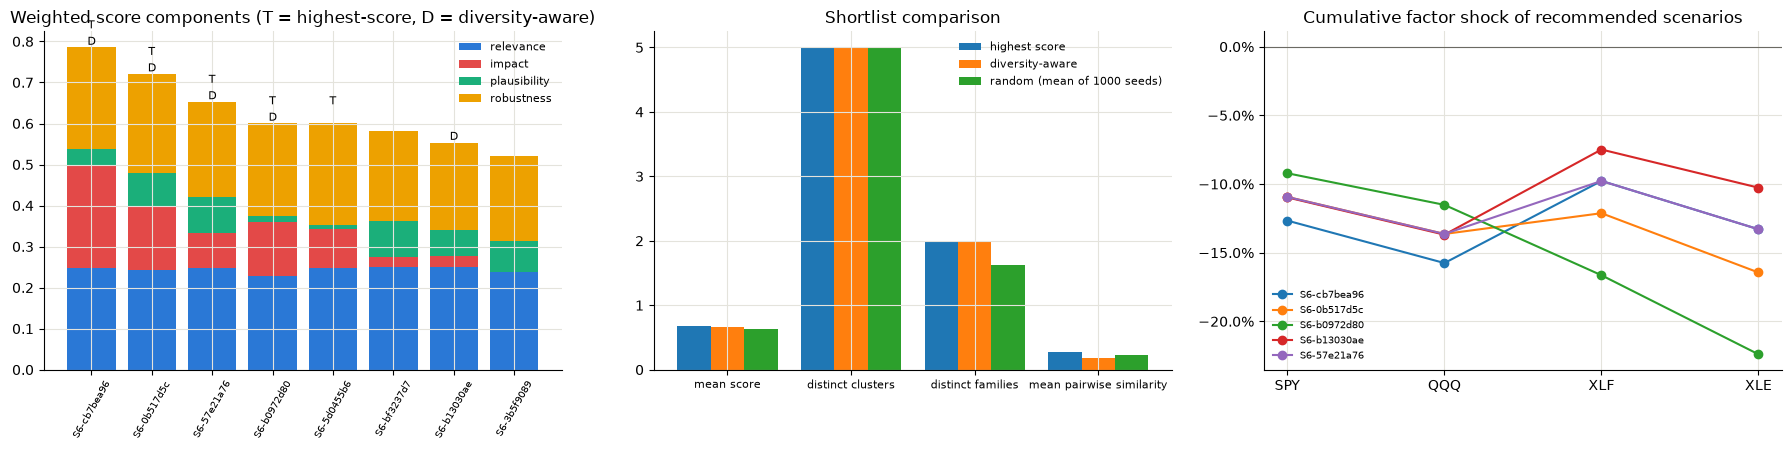

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
e = S[S["eligible"]].set_index("scenario_id").sort_values("score", ascending=False)
bottom = np.zeros(len(e))
for c, col in zip(COMPONENTS, ["#2a78d6", "#e34948", "#1baf7a", "#eda100"]):
    vals = RCFG.weights[c] * e[c].to_numpy()
    axes[0].bar(e.index, vals, bottom=bottom, color=col, label=c); bottom += vals
for i, sid in enumerate(e.index):
    if sid in div_ids:
        axes[0].annotate("D", (i, bottom[i]), ha="center", va="bottom", fontsize=8)
    if sid in top_ids:
        axes[0].annotate("T", (i, bottom[i] + 0.04), ha="center", va="bottom", fontsize=8)
axes[0].set_title("Weighted score components (T = highest-score, D = diversity-aware)"); axes[0].tick_params(axis="x", rotation=60, labelsize=7)
axes[0].legend(frameon=False, fontsize=8)
m = comparison[["mean score", "distinct clusters", "distinct families", "mean pairwise similarity"]]
x = np.arange(len(m.columns))
for j, (name, row) in enumerate(m.iterrows()):
    axes[1].bar(x + (j - 1) * 0.27, row.to_numpy(dtype=float), width=0.27, label=name)
axes[1].set_xticks(x, m.columns, fontsize=8); axes[1].set_title("Shortlist comparison"); axes[1].legend(frameon=False, fontsize=8)
for sid in div_ids:
    p = np.array(rows_by_id.loc[sid, "cum_factor_return"]) * 100
    axes[2].plot(names, p, marker="o", label=sid)
axes[2].axhline(0, color="#6b6a63", linewidth=0.8); axes[2].yaxis.set_major_formatter(PercentFormatter())
axes[2].set_title("Cumulative factor shock of recommended scenarios"); axes[2].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

## 10. Save outputs, assertions and summary

In [11]:
previous = json.loads(PREVIOUS_OUTPUT.read_text())
score_gap_pct = 100 * (comparison.loc["highest score", "mean score"] - comparison.loc["diversity-aware", "mean score"]) / comparison.loc["highest score", "mean score"]
summary = {
    "in_sample": f"In-sample (Stage 6 reporting seeds {REPORT_SEEDS.start}-{REPORT_SEEDS.stop - 1}, also used by Stage 7 for eligibility and the robustness score): "
                 f"the diversity-aware shortlist's mean score is {score_gap_pct:.1f}% lower than the highest-score shortlist; mean P(valid) "
                 f"{comparison_eval.loc[('diversity-aware', 'in-sample'), 'mean P(valid)']:.1%} vs {comparison_eval.loc[('highest score', 'in-sample'), 'mean P(valid)']:.1%}.",
    "independent": f"Independent ({len(FRESH_SEEDS)} fresh validation seeds {FRESH_SEEDS.start}-{FRESH_SEEDS.stop - 1}, unused by any selection): mean P(valid) "
                    f"diversity-aware {comparison_eval.loc[('diversity-aware', 'independent'), 'mean P(valid)']:.1%} (min {comparison_eval.loc[('diversity-aware', 'independent'), 'min P(valid)']:.1%}), "
                    f"highest score {comparison_eval.loc[('highest score', 'independent'), 'mean P(valid)']:.1%} (min {comparison_eval.loc[('highest score', 'independent'), 'min P(valid)']:.1%}), "
                    f"random {comparison_eval.loc[(f'random (mean of {len(RANDOM_SEEDS)} seeds)', 'independent'), 'mean P(valid)']:.1%}. The ranking was not changed by this evaluation.",
    "scope": "validation-period residual draws only; the gated 2024-2025 test-split evaluation has not been run",
}
output = {"stage": 7, "schema_version": "stage7.v2", "generated_utc": pd.Timestamp.now(tz="UTC").isoformat(),
          "provenance": {"library_path": str(LIBRARY_PATH.relative_to(PROJECT_ROOT)), "library_sha256": LIB_SHA, "library_generated_utc": meta["generated_utc"],
                         "shock_model": str((PROJECT_ROOT / SIM.output_dir / "shock_model.json").relative_to(PROJECT_ROOT)), "test_split_used": False,
                         "supersedes": {"path": str(PREVIOUS_OUTPUT.relative_to(PROJECT_ROOT)), "sha256": library_fingerprint(PREVIOUS_OUTPUT),
                                        "changes": "independent fresh evaluation added; exact +-0.05 weight shifts; full robust_action_path and provenance per recommendation; "
                                                   "in-sample and independent metrics separated. Eligibility, weights, scores and ranking unchanged."}},
          "config": dataclasses.asdict(RCFG), "portfolio_profiles": {n: p.summary() for n, p in profiles.items()},
          "eligibility": features[["scenario_id", "status", "eligible", "ineligible_reason"]].to_dict("records"),
          "shortlists": {"highest_score": top_ids, "diversity_aware": div, "random_seeds": [RANDOM_SEEDS.start, RANDOM_SEEDS.stop - 1]},
          "recommendations": recs, "comparison_in_sample": comparison.reset_index().to_dict("records"),
          "comparison_robustness": comparison_eval.reset_index().to_dict("records"),
          "independent_evaluation": {"seeds": [FRESH_SEEDS.start, FRESH_SEEDS.stop - 1], "episodes_per_scenario": len(FRESH_SEEDS),
                                     "anchors": "validation split", "residual_mode": SIM.residual_mode, "path": "robust_action_path (5 days, open loop)",
                                     "seed_register": {n: [r.start, r.stop - 1] for n, r in UPSTREAM_SEEDS.items()}, "seeds_independent": seeds_independent,
                                     "reporting_reproduction": {"scenario_id": elig_ids[0], "reproduced": bool(reporting_reproduced)},
                                     "used_for_ranking": False, "per_scenario": fresh.reset_index().to_dict("records")},
          "stability": stability.to_dict("records"), "summary": summary,
          "coverage": gaps.to_dict("records"), "runtime_seconds": {"replay": replay_runtime, "evaluation": eval_runtime, "independent_evaluation": fresh_runtime}}
from rlstress.scenario_library import to_json
OUT_DIR.mkdir(parents=True, exist_ok=True)
def same_json(a, b):
    """Equal after JSON round trip; floats compared to 1e-9 relative."""
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(same_json(a[k], b[k]) for k in a)
    if isinstance(a, list):
        return isinstance(b, list) and len(a) == len(b) and all(same_json(x, y) for x, y in zip(a, b))
    if isinstance(a, float) and isinstance(b, (int, float)):
        return bool(np.isclose(a, b, rtol=1e-9, atol=1e-12))
    return a == b
if OUT_PATH.exists() and not OVERWRITE:
    # The v2 file is frozen (Stage 8 manifest). A re-run must reproduce it exactly (timestamps and runtimes excepted); it is not rewritten.
    stored_v2, rerun_v2 = json.loads(OUT_PATH.read_text()), json.loads(to_json(output))
    for k in ("generated_utc", "runtime_seconds"):
        stored_v2.pop(k, None); rerun_v2.pop(k, None)
    assert same_json(stored_v2, rerun_v2), f"re-run does not reproduce the frozen {OUT_PATH.name} (not rewritten)"
    v2_action = "verified the frozen file (reproduced exactly, not rewritten)"
else:
    OUT_PATH.write_text(to_json(output))
    v2_action = "wrote"

checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})
check("all recommended scenarios eligible", all(rows_by_id.loc[i, "eligible"] for i in set(top_ids) | set(div_ids)))
check("weights sum to 1", np.isclose(sum(RCFG.weights.values()), 1.0))
check("components within [0, 1]", all(S.loc[S["eligible"], c].between(0, 1).all() for c in COMPONENTS))
check("selections deterministic", select_top(S, RCFG.top_k) == top_ids and [d["scenario_id"] for d in select_diverse(S, RCFG.top_k, RCFG)] == div_ids)
check("replay reproduces Stage 6 drawdowns", consistency < 1e-9, f"max diff {consistency:.1e}")
check("provenance preserved (representative candidate per recommendation)", all(isinstance(rows_by_id.loc[i, "representative_candidate_id"], str) for i in div_ids))
check("no missing evidence among eligible", not S.loc[S["eligible"], ["rank", "p_valid", "p_valid_ci_low", "p_implausible", "reporting_episodes"]].isna().any().any())
check("Stage 4-6 results unchanged", {n: tree_hash(p) for n, p in PROTECTED.items()} == HASH_BEFORE)
check("library file unchanged", library_fingerprint(LIBRARY_PATH) == LIB_SHA)
check("output written and readable", json.loads(OUT_PATH.read_text())["provenance"]["library_sha256"] == LIB_SHA)
prev_div = [d["scenario_id"] for d in previous["shortlists"]["diversity_aware"]]
check("ranking unchanged vs v1 (both shortlists, order and scores)", previous["shortlists"]["highest_score"] == top_ids and prev_div == div_ids
      and np.allclose([d["adjusted_score"] for d in previous["shortlists"]["diversity_aware"]], [d["adjusted_score"] for d in div]), f"{div_ids}")
check("eligibility and weights unchanged vs v1", previous["eligibility"] == json.loads(to_json(features[["scenario_id", "status", "eligible", "ineligible_reason"]].to_dict("records")))
      and previous["config"]["weights"] == RCFG.weights)
check("fresh seeds disjoint from every upstream seed range", seeds_independent, f"{FRESH_SEEDS.start}-{FRESH_SEEDS.stop - 1}")
check("fresh evaluation: 500 episodes per eligible scenario on the same seed list", fresh_seed_lists_ok and len(fresh) == int(S["eligible"].sum())
      and (fresh["episodes"] == 500).all() and len(FRESH_SEEDS) == 500, f"{len(fresh)} scenarios")
check("evaluation pipeline reproduces Stage 6 reporting values", bool(reporting_reproduced), elig_ids[0])
check("weight shifts exact (+-0.05; others -+0.05/3; sum 1)", len(weight_rows) == 8 and all(
      np.isclose(r[f"w {r['perturbation'].split()[1]}"], 0.25 + float(r["perturbation"].split()[2]))
      and all(np.isclose(r[f"w {c}"], 0.25 - float(r["perturbation"].split()[2]) / 3) for c in COMPONENTS if c != r["perturbation"].split()[1])
      and np.isclose(sum(r[f"w {c}"] for c in COMPONENTS), 1.0) for _, r in weight_rows.iterrows()))
written = json.loads(OUT_PATH.read_text())
check("robust_action_path complete (5 x 4) and identical to the library for every recommendation",
      all(np.asarray(r["robust_action_path"]).shape == (H, len(FACTOR_ORDER)) and r["robust_action_path"] == lib_by_id[r["scenario_id"]]["robust_action_path"]
          and np.allclose(r["robust_action_path"][: r["executed_days"]], lib_by_id[r["scenario_id"]]["action_path"]) for r in written["recommendations"]))
REQUIRED = {"stage", "schema_version", "provenance", "config", "eligibility", "shortlists", "recommendations", "comparison_in_sample",
            "comparison_robustness", "independent_evaluation", "stability", "summary", "coverage"}
REC_REQUIRED = {"rank", "scenario_id", "robust_action_path", "provenance", "evidence_in_sample", "evidence_independent", "explanation"}
check("output schema (top-level and per-recommendation keys)", REQUIRED <= set(written) and all(REC_REQUIRED <= set(r) for r in written["recommendations"]))
checks_df = pd.DataFrame(checks)
display(checks_df.style.hide(axis="index").map(lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))
assert (checks_df["result"] == "PASS").all()
print(f"{len(checks_df)}/{len(checks_df)} checks PASS | {v2_action}: {OUT_PATH.relative_to(PROJECT_ROOT)}")
print(f"Library {len(features)} scenarios, eligible {int(S['eligible'].sum())}; diversity-aware shortlist {div_ids}; missing families {missing}")
for k, v in summary.items():
    print(f"- {k}: {v}")

check,result,detail
all recommended scenarios eligible,PASS,
weights sum to 1,PASS,
"components within [0, 1]",PASS,
selections deterministic,PASS,
replay reproduces Stage 6 drawdowns,PASS,max diff 0.0e+00
provenance preserved (representative candidate per recommendation),PASS,
no missing evidence among eligible,PASS,
Stage 4-6 results unchanged,PASS,
library file unchanged,PASS,
output written and readable,PASS,


18/18 checks PASS | verified the frozen file (reproduced exactly, not rewritten): results/stage7/recommendations.json
Library 16 scenarios, eligible 8; diversity-aware shortlist ['S6-cb7bea96', 'S6-0b517d5c', 'S6-b0972d80', 'S6-b13030ae', 'S6-57e21a76']; missing families ['technology-led', 'financial-led', 'energy-led', 'mixed-direction']
- in_sample: In-sample (Stage 6 reporting seeds 20000-20499, also used by Stage 7 for eligibility and the robustness score): the diversity-aware shortlist's mean score is 1.4% lower than the highest-score shortlist; mean P(valid) 94.8% vs 97.2%.
- independent: Independent (500 fresh validation seeds 30000-30499, unused by any selection): mean P(valid) diversity-aware 96.5% (min 91.4%), highest score 98.2% (min 96.0%), random 95.5%. The ranking was not changed by this evaluation.
- scope: validation-period residual draws only; the gated 2024-2025 test-split evaluation has not been run


## 11. Limitations
- Recommendations can only be as diverse as the Stage 6 library; families absent from it (technology-, financial-, energy-only, mixed-direction) are reported as gaps.
- Relevance uses the Stage 4 linear factor loadings (model-implied sensitivity); impact is an exact replay but of a model path with i.i.d. daily shocks and tails lighter than history.
- Equal weights and λ = 0.5 are declared defaults, not optimised; the stability table shows how much the shortlist depends on them.
- Eligibility and the robustness score use the Stage 6 reporting episodes, so shortlist metrics built on them are in-sample. The independent check (500 fresh seeds) is still validation-period residual draws on the same anchors and model; the gated test-split evaluation has not been run.
- This is a ranking aid for stress testing, not investment advice and not an automated trading system.

## 12. Extension: expanded scenario catalog

**Why.** Sections 1–11 recommend 5 of only 8 eligible scenarios, which leaves the ranker little to do. This extension
enlarges the catalog **inside Stage 7**. It does not re-run Stage 5 or 6 and does not change the frozen v2 outputs above.

**How.** Each of the 16 Stage 6 paths (`robust_action_path`, 5 days × 4 factors) is transformed into variants:

| Transform | Variants |
|---|---|
| Intensity | × 0.85, 0.90, 0.95, 1.05, 1.10, 1.15 |
| Timing | reversed days; front-loaded (worst day first); back-loaded |
| Factor tilt (SPY, QQQ, XLF, XLE multipliers) | technology (0.7, 1.3, 1, 1), strong technology (0.5, 1.5, 1, 1), financials (1, 1, 1.4, 0.6), energy (1, 1, 0.6, 1.4), equity (1.1, 1.1, 0.5, 0.5), sectors (0.6, 0.6, 1.3, 1.3) |

The tilts untie SPY from QQQ and XLF from XLE. That is the restriction that made technology-, financial- and
energy-led paths unreachable for the nine grouped actions (section 8).

**Same validation protocol as Stage 6** (thresholds unchanged):
1. Deterministic replay (`residual_mode = "mean"`). Keep valid breaches (rank ≥ q).
2. Near-duplicates (distance ≤ the Stage 6 one-step cut, 0.335) are merged. A group keeps its Stage 6 scenario if it
   has one; otherwise it keeps the most plausible path. This uses no episodes.
3. Screening: P(valid) ≥ 80% on seeds 10000–10199 makes a path **validated** (selection only).
4. Reporting: 500 episodes on seeds 20000–20499. Eligibility and the robustness score are computed exactly as in sections 4–5.
5. Independent evaluation: fresh seeds 30000–30499, never used for selection.

All anchors are validation dates. **The 2024–2025 test split is not used.** The 16 Stage 6 scenarios keep their
stored library values; the re-run is checked to reproduce them.

In [12]:
import hashlib
from rlstress.scenario_library import classify_family, cluster_features, cumulative_feature, factor_shock_path, sequence_key

EXT_DIR = PROJECT_ROOT / "results" / "stage7_extension"          # separate from the frozen results/stage7
EXT_PATH = EXT_DIR / "extended_catalog.json"
EXT_OVERWRITE = False
V2_SHA = library_fingerprint(OUT_PATH)                            # frozen v2 recommendations (Stage 8 manifest prefix 045dfb911fa1)
assert V2_SHA.startswith("045dfb911fa1"), "frozen Stage 7 v2 output changed"
SCALES = (0.85, 0.90, 0.95, 1.05, 1.10, 1.15)
TILTS = {"technology tilt": (0.7, 1.3, 1.0, 1.0), "strong technology tilt": (0.5, 1.5, 1.0, 1.0),
         "financials tilt": (1.0, 1.0, 1.4, 0.6), "energy tilt": (1.0, 1.0, 0.6, 1.4),
         "equity tilt": (1.1, 1.1, 0.5, 0.5), "sector tilt": (0.6, 0.6, 1.3, 1.3)}
NEAR_DUP_CUT, CLUSTER_CUT = meta["clustering"]["near_duplicate_cut"], meta["clustering"]["cluster_cut"]
FAMILY_DELTA = meta["family_rules"]["delta"]
P_VALID_TARGET = meta["selection_rule"]["p_valid_target"]
BOUNDS = np.array([meta["factor_bounds"][n] for n in names])
DIRICHLET_SEED, N_RANDOM_PORTFOLIOS = 5_000, 100                 # portfolio-sampling RNG only (no episodes)

def variants(A):
    """Transformed copies of a 5 x 4 action path, clipped to the action bound."""
    order = np.argsort(A.sum(axis=1))                             # most negative day first
    out = {f"intensity x{c:.2f}": A * c for c in SCALES}
    out.update({"reversed days": A[::-1], "front-loaded": A[order], "back-loaded": A[order[::-1]]})
    out.update({name: A * np.array(m) for name, m in TILTS.items()})
    return {k: np.clip(v, -1.0, 1.0) for k, v in out.items()}

t0 = time.perf_counter()
cands = {}
for s in library["scenarios"]:                                    # originals first, so they keep their identity
    A = np.asarray(s["robust_action_path"], dtype=float)
    cands[sequence_key(A)] = {"parent": s["scenario_id"], "variant": "original", "path": A}
for s in library["scenarios"]:
    for vname, P in variants(np.asarray(s["robust_action_path"], dtype=float)).items():
        cands.setdefault(sequence_key(P), {"parent": s["scenario_id"], "variant": vname, "path": P})
n_generated = len(library["scenarios"]) * (1 + len(SCALES) + 3 + len(TILTS))

det_env = build_env(dataclasses.replace(CFG, simulation=dataclasses.replace(SIM, residual_mode="mean")), source, model, SIM.min_plausibility, "validation")
det_anchor = det_env.market_states.index[len(det_env.market_states) // 2]
for key, c in cands.items():
    r = evaluate_path(det_env, c["path"], det_anchor, SEED)
    c.update(key=key, valid=bool(r["valid"]), breached=bool(r["breached"]), rank=float(r["rank"]), drawdown=float(r["drawdown"]), days=int(r["days"]))
    c["family"] = classify_family(c["path"][: c["days"]], FAMILY_DELTA) if c["days"] else "unclassified"
    c["feature"] = cumulative_feature(c["path"], c["days"])
    c["id"] = c["parent"] if c["variant"] == "original" else "S7X-" + hashlib.sha1(key.encode()).hexdigest()[:8]
originals = [c for c in cands.values() if c["variant"] == "original"]
det_diff = max(max(abs(c["rank"] - lib_by_id[c["id"]]["deterministic_rank"]), abs(c["drawdown"] - lib_by_id[c["id"]]["deterministic_drawdown"]))
               for c in originals)
det_days_ok = all(c["days"] == lib_by_id[c["id"]]["executed_days"] for c in originals)
print(f"Deterministic replay of {len(cands)} unique paths in {time.perf_counter() - t0:.1f}s; Stage 6 originals reproduced "
      f"(max |diff| {det_diff:.1e}, executed days match: {det_days_ok})")
assert det_diff < 1e-9 and det_days_ok

# Near-duplicate merge among deterministic valid paths (no episodes): keep the Stage 6 scenario, else the most plausible path.
valid_c = [c for c in cands.values() if c["valid"]]
groups = cluster_features(np.vstack([c["feature"] for c in valid_c]), NEAR_DUP_CUT)
reps = []
for g in sorted(set(groups)):
    members = [c for c, gi in zip(valid_c, groups) if gi == g]
    orig = [c for c in members if c["variant"] == "original"]
    keep = orig or [max(members, key=lambda c: (c["rank"], c["drawdown"], c["key"]))]
    for c in keep:
        c["group_size"] = len(members)
    reps.extend(keep)
cand_table = pd.DataFrame([{k: c[k] for k in ("variant", "breached", "valid")} for c in cands.values()]).groupby("variant")[["breached", "valid"]].mean()
display(cand_table.style.format("{:.0%}").set_caption("Deterministic breach and valid-breach share by transform"))
funnel = {"generated variants (incl. originals)": n_generated, "unique paths": len(cands), "deterministic breaches": sum(c["breached"] for c in cands.values()),
          "deterministic valid breaches": len(valid_c), "near-duplicate groups": int(len(set(groups))), "catalog candidates after merge": len(reps)}
display(pd.DataFrame([funnel]).T.rename(columns={0: "count"}).style.set_caption("Extension funnel (before robustness)"))
display(pd.Series([c["family"] for c in reps]).value_counts().to_frame("candidates").style.set_caption("Families among catalog candidates"))

Deterministic replay of 255 unique paths in 1.5s; Stage 6 originals reproduced (max |diff| 0.0e+00, executed days match: True)


,breached,valid
variant,,
back-loaded,100%,100%
energy tilt,100%,88%
equity tilt,69%,56%
financials tilt,100%,88%
front-loaded,100%,75%
intensity x0.85,31%,31%
intensity x0.90,50%,50%
intensity x0.95,62%,62%
intensity x1.05,100%,100%


,count
generated variants (incl. originals),256
unique paths,255
deterministic breaches,210
deterministic valid breaches,170
near-duplicate groups,82
catalog candidates after merge,82


,candidates
broad-market,53
sector-led (financials and energy jointly),12
technology-led,7
energy-led,5
financial-led,5


In [13]:
# 12b. Robustness: screening (selection) -> validated -> reporting (Stage 6 protocol, validation anchors, sampled residuals)
t0 = time.perf_counter()
ext_scenarios, screen_repro = [], []
for c in reps:
    pol = OpenLoopPolicy(c["path"], OBS, c["id"])
    scr = robustness_summary(evaluate_policy(eval_env, pol, SCREEN_SEEDS))
    if c["variant"] == "original":                                   # keep the stored Stage 6 record; check that screening reproduces it
        s = dict(lib_by_id[c["id"]])
        screen_repro.append(np.isclose(scr["p_valid"], s["screening_p_valid"]) and s["status"] == ("validated" if scr["p_valid"] >= P_VALID_TARGET else "exploratory"))
        s.update(stage6_cluster=s["cluster"], origin="Stage 6 library", parent=c["id"], variant="original")
    else:
        validated = scr["p_valid"] >= P_VALID_TARGET
        rep = robustness_summary(evaluate_policy(eval_env, pol, REPORT_SEEDS)) if validated else None
        executed = c["path"][: c["days"]]
        s = {"scenario_id": c["id"], "status": "validated" if validated else "exploratory",
             "selection_reason": (f"deterministic valid breach (rank {c['rank']:.4f} >= q = {RCFG.q}) and screening P(valid) {scr['p_valid']:.1%} "
                                  f"{'>=' if validated else '<'} {P_VALID_TARGET:.0%}"),
             "family": c["family"], "discovery_methods": [f"Stage 7 augmentation ({c['variant']} of {c['parent']})"],
             "representative_candidate_id": c["id"], "executed_days": c["days"], "action_path": executed.tolist(),
             "factor_shock_path": factor_shock_path(executed, BOUNDS).tolist(), "robust_action_path": c["path"].tolist(),
             "robust_factor_shock_path": factor_shock_path(c["path"], BOUNDS).tolist(),
             "deterministic_rank": c["rank"], "deterministic_drawdown": c["drawdown"], "deterministic_breach_day": c["days"],
             "p_valid": rep["p_valid"] if rep else None, "p_valid_ci95": rep["p_valid_ci95"] if rep else None,
             "p_any_breach": rep["p_any_breach"] if rep else None, "p_implausible": rep["p_implausible"] if rep else None,
             "mean_drawdown_at_breach": rep["mean_drawdown_at_breach"] if rep else None, "mean_breach_day": rep["mean_breach_day"] if rep else None,
             "screening_p_valid": scr["p_valid"], "screening_episodes": scr["episodes"], "reporting_episodes": rep["episodes"] if rep else 0,
             "stage6_cluster": None, "origin": "Stage 7 augmentation", "parent": c["parent"], "variant": c["variant"]}
    s["near_duplicate_group_size"] = c["group_size"]
    ext_scenarios.append(s)
robust_runtime = time.perf_counter() - t0
ext_clusters = cluster_features(np.vstack([cumulative_feature(np.asarray(s["robust_action_path"]), s["executed_days"]) for s in ext_scenarios]), CLUSTER_CUT)
for s, cl in zip(ext_scenarios, ext_clusters):
    s["cluster"] = int(cl)                                              # clusters of the extended catalog (same cut as Stage 6)
ext_library = {"metadata": meta, "scenarios": ext_scenarios}
ext_by_id = {s["scenario_id"]: s for s in ext_scenarios}
XF = eligibility(scenario_features(ext_library, model.factor_sd, H), RCFG)
XF["origin"] = XF["scenario_id"].map(lambda i: ext_by_id[i]["origin"])
originals_reproduced = all(screen_repro) and len(screen_repro) == len(library["scenarios"])
print(f"Robustness for {len(reps)} catalog candidates in {robust_runtime:.0f}s; Stage 6 screening reproduced for all 16 originals: {originals_reproduced}")
assert originals_reproduced
catalog_sizes = pd.DataFrame({
    "original (Stage 6)": [len(features), int((features["status"] == "validated").sum()), int(features["eligible"].sum()), features.loc[features["eligible"], "family"].nunique()],
    "extended (this section)": [len(XF), int((XF["status"] == "validated").sum()), int(XF["eligible"].sum()), XF.loc[XF["eligible"], "family"].nunique()]},
    index=["scenarios", "validated", "eligible", "eligible families"])
display(catalog_sizes.style.set_caption("Catalog size: Stage 6 library vs extended catalog"))
display(XF.groupby(["family", "origin"])["eligible"].agg(["size", "sum"]).rename(columns={"size": "scenarios", "sum": "eligible"})
        .style.set_caption("Extended catalog by family and origin"))
ext_gaps = coverage_gaps(XF)
display(ext_gaps.style.hide(axis="index").set_caption("Target families in the extended catalog"))

Robustness for 82 catalog candidates in 206s; Stage 6 screening reproduced for all 16 originals: True


,original (Stage 6),extended (this section)
scenarios,16,82
validated,8,35
eligible,8,34
eligible families,2,5


family,in library,eligible
broad-market,True,True
technology-led,True,True
financial-led,True,True
energy-led,True,True
mixed-direction,False,False


## 13. Alternative recommenders on both catalogs

Every recommender uses the same eligible pool and returns k = 5. The two Stage 7 methods are compared with single-signal baselines:

| Recommender | Ranks eligible scenarios by |
|---|---|
| highest score | the weighted score (equal weights, section 5) |
| diversity-aware | score − λ · max similarity (section 6) |
| robustness only (popularity-style) | Wilson lower bound of P(valid): the "most reliable" scenarios for everyone |
| severity only | replayed drawdown of this portfolio |
| relevance only (content similarity) | cosine between the scenario's shock and the portfolio's loss direction |
| plausibility only | plausibility margin |
| random | uniform draw, mean over 1,000 RNG seeds |

**Shortlist metrics.** The in-sample columns come from Stage 6 reporting seeds, which eligibility also uses. The
independent columns come from fresh seeds 30000–30499.

**Across portfolios.** The metrics are computed on the 4 profiles plus 100 random long-only portfolios (Dirichlet(1) weights, RNG seed 5000):
- **personalisation:** 1 − mean pairwise Jaccard overlap between the lists of different portfolios;
- **catalog coverage:** share of eligible scenarios recommended to at least one portfolio;
- **non-broad-market share:** share of portfolios that receive at least one scenario outside the broad-market family.

There is still no ground-truth relevance label, so ranking-accuracy metrics (NDCG, hit rate) are not reported.

In [14]:
# 13a. Scores, shortlists and the independent evaluation (default portfolio)
K = RCFG.top_k
def select_by(scored, col, k):
    """Top-k eligible scenarios by one column (ties by scenario_id)."""
    return list(scored[scored["eligible"]].sort_values([col, "scenario_id"], ascending=[False, True])["scenario_id"].head(k))
RECOMMENDERS = {
    "highest score": lambda Sx: select_top(Sx, K),
    "diversity-aware": lambda Sx: [d["scenario_id"] for d in select_diverse(Sx, K, RCFG)],
    "robustness only (popularity-style)": lambda Sx: select_by(Sx, "robustness", K),
    "severity only": lambda Sx: select_by(Sx, "portfolio_drawdown", K),
    "relevance only (content similarity)": lambda Sx: select_by(Sx, "relevance", K),
    "plausibility only": lambda Sx: select_by(Sx, "plausibility", K),
}
XE = XF[XF["eligible"]]

def portfolio_impacts(w, feats):
    """Replayed drawdown of each scenario for weights ``w`` (deterministic residuals, as section 4)."""
    pcfg = dataclasses.replace(CFG, portfolio=dataclasses.replace(CFG.portfolio, weights=tuple(float(x) for x in w)),
                               simulation=dataclasses.replace(SIM, residual_mode="mean"))
    env = build_env(pcfg, source, model, SIM.min_plausibility, "train")
    anchor = env.market_states.index[len(env.market_states) // 2]
    return {r.scenario_id: float(evaluate_path(env, np.asarray(r.padded_action_path), anchor, SEED)["drawdown"]) for r in feats.itertuples()}

t0 = time.perf_counter()
ext_impacts = {name: portfolio_impacts(w, XE) for name, w in PORTFOLIOS.items()}
impact_repro = max(abs(ext_impacts[n][i] - impacts[n][i]) for n in PORTFOLIOS for i in elig_ids)
assert impact_repro < 1e-9, "extended replay does not reproduce the section 4 impacts"
SX = score(XF, profiles[default], ext_impacts[default], RCFG)

# Independent evaluation of every eligible extended scenario (Stage 6 originals reuse section 7b: same seeds, same path).
new_elig = sorted(set(XE["scenario_id"]) - set(elig_ids))
ext_fresh_rows = []
for sid in new_elig:
    s_ = robustness_summary(evaluate_policy(eval_env, OpenLoopPolicy(np.asarray(ext_by_id[sid]["robust_action_path"], dtype=float), OBS, sid), FRESH_SEEDS))
    ext_fresh_rows.append({"scenario_id": sid, "episodes": s_["episodes"], "p_valid": s_["p_valid"], "p_valid_ci_low": s_["p_valid_ci95"][0],
                           "p_valid_ci_high": s_["p_valid_ci95"][1], "p_any_breach": s_["p_any_breach"], "p_implausible": s_["p_implausible"],
                           "median_valid_rank": s_["median_valid_rank"], "mean_drawdown_at_breach": s_["mean_drawdown_at_breach"], "mean_breach_day": s_["mean_breach_day"]})
ext_fresh = pd.concat([fresh.drop(columns=["first_seed", "last_seed"]), pd.DataFrame(ext_fresh_rows).set_index("scenario_id")]) if ext_fresh_rows else fresh
ext_fresh_runtime = time.perf_counter() - t0
x_in_sample = XE.set_index("scenario_id")[["p_valid", "p_implausible", "reporting_episodes"]].rename(columns={"reporting_episodes": "episodes"})
x_in_sample["mean_drawdown_at_breach"] = [ext_by_id[i]["mean_drawdown_at_breach"] for i in x_in_sample.index]
print(f"Impacts for {len(XE)} eligible scenarios x {len(PORTFOLIOS)} portfolios (section 4 values reproduced, max |diff| {impact_repro:.1e}); "
      f"independent evaluation of {len(new_elig)} new eligible scenarios x {len(FRESH_SEEDS)} episodes; {ext_fresh_runtime:.0f}s")

def recommender_table(Sx, fresh_tab, in_tab):
    rows = []
    for name, fn in RECOMMENDERS.items():
        ids = fn(Sx)
        ins, ind = shortlist_fresh_metrics(in_tab, ids), shortlist_fresh_metrics(fresh_tab, ids)
        m = shortlist_metrics(Sx, ids, RCFG)
        rows.append({"recommender": name, "mean score": m["mean score"], "mean relevance": m["mean relevance"], "mean portfolio drawdown": m["mean portfolio drawdown"],
                     "in-sample mean P(valid)": ins["fresh mean P(valid)"], "independent mean P(valid)": ind["fresh mean P(valid)"],
                     "independent min P(valid)": ind["fresh min P(valid)"], "distinct clusters": m["distinct clusters"], "distinct families": m["distinct families"],
                     "mean pairwise similarity": m["mean pairwise similarity"], "shortlist": ", ".join(ids)})
    rnd = []
    for s in RANDOM_SEEDS:
        ids = select_random(Sx, K, s)
        m = shortlist_metrics(Sx, ids, RCFG)
        rnd.append({"mean score": m["mean score"], "mean relevance": m["mean relevance"], "mean portfolio drawdown": m["mean portfolio drawdown"],
                    "in-sample mean P(valid)": shortlist_fresh_metrics(in_tab, ids)["fresh mean P(valid)"],
                    "independent mean P(valid)": shortlist_fresh_metrics(fresh_tab, ids)["fresh mean P(valid)"],
                    "independent min P(valid)": shortlist_fresh_metrics(fresh_tab, ids)["fresh min P(valid)"], "distinct clusters": m["distinct clusters"],
                    "distinct families": m["distinct families"], "mean pairwise similarity": m["mean pairwise similarity"]})
    rows.append({"recommender": f"random (mean of {len(RANDOM_SEEDS)} seeds)", **pd.DataFrame(rnd).mean().to_dict(), "shortlist": "—"})
    return pd.DataFrame(rows).set_index("recommender")

FMT = {"mean score": "{:.3f}", "mean relevance": "{:.3f}", "mean portfolio drawdown": "{:.2%}", "in-sample mean P(valid)": "{:.1%}",
       "independent mean P(valid)": "{:.1%}", "independent min P(valid)": "{:.1%}", "distinct clusters": "{:.1f}", "distinct families": "{:.1f}",
       "mean pairwise similarity": "{:.3f}"}
cmp_original = recommender_table(S, fresh, in_sample)
cmp_extended = recommender_table(SX, ext_fresh, x_in_sample)
assert cmp_original.loc["highest score", "shortlist"] == ", ".join(top_ids) and cmp_original.loc["diversity-aware", "shortlist"] == ", ".join(div_ids)
display(cmp_original.style.format(FMT, na_rep="—").set_caption(f"Original catalog ({int(S['eligible'].sum())} eligible), default portfolio"))
display(cmp_extended.style.format(FMT, na_rep="—").set_caption(f"Extended catalog ({int(SX['eligible'].sum())} eligible), default portfolio"))

Impacts for 34 eligible scenarios x 4 portfolios (section 4 values reproduced, max |diff| 0.0e+00); independent evaluation of 26 new eligible scenarios x 500 episodes; 89s


,mean score,mean relevance,mean portfolio drawdown,in-sample mean P(valid),independent mean P(valid),independent min P(valid),distinct clusters,distinct families,mean pairwise similarity,shortlist
recommender,,,,,,,,,,
highest score,0.672,0.971,12.47%,97.2%,98.2%,96.0%,5.0,2.0,0.268,"S6-cb7bea96, S6-0b517d5c, S6-57e21a76, S6-b0972d80, S6-5d0455b6"
diversity-aware,0.663,0.973,12.34%,94.8%,96.5%,91.4%,5.0,2.0,0.187,"S6-cb7bea96, S6-0b517d5c, S6-b0972d80, S6-b13030ae, S6-57e21a76"
robustness only (popularity-style),0.672,0.971,12.47%,97.2%,98.2%,96.0%,5.0,2.0,0.268,"S6-5d0455b6, S6-cb7bea96, S6-0b517d5c, S6-57e21a76, S6-b0972d80"
severity only,0.672,0.971,12.47%,97.2%,98.2%,96.0%,5.0,2.0,0.268,"S6-cb7bea96, S6-0b517d5c, S6-b0972d80, S6-5d0455b6, S6-57e21a76"
relevance only (content similarity),0.635,0.992,12.04%,94.8%,96.0%,91.4%,5.0,1.0,0.259,"S6-b13030ae, S6-bf3237d7, S6-cb7bea96, S6-5d0455b6, S6-57e21a76"
plausibility only,0.606,0.982,11.69%,91.6%,93.6%,89.2%,5.0,1.0,0.248,"S6-bf3237d7, S6-57e21a76, S6-0b517d5c, S6-3b5f9089, S6-b13030ae"
random (mean of 1000 seeds),0.626,0.976,12.03%,93.9%,95.5%,90.1%,5.0,1.6,0.225,—


,mean score,mean relevance,mean portfolio drawdown,in-sample mean P(valid),independent mean P(valid),independent min P(valid),distinct clusters,distinct families,mean pairwise similarity,shortlist
recommender,,,,,,,,,,
highest score,0.766,0.979,13.03%,99.1%,99.4%,98.8%,4.0,1.0,0.337,"S7X-a312a53e, S6-cb7bea96, S7X-6bea5299, S7X-c63e8646, S6-0b517d5c"
diversity-aware,0.765,0.981,13.22%,99.4%,99.7%,98.8%,5.0,1.0,0.272,"S7X-a312a53e, S7X-6bea5299, S7X-cd64df2f, S7X-c63e8646, S6-cb7bea96"
robustness only (popularity-style),0.646,0.983,11.62%,100.0%,100.0%,100.0%,2.0,1.0,0.357,"S6-5d0455b6, S6-cb7bea96, S7X-06647fbd, S7X-44fc1fbe, S7X-f096b5f4"
severity only,0.759,0.978,13.23%,99.3%,99.4%,97.2%,5.0,2.0,0.271,"S7X-cd64df2f, S6-cb7bea96, S7X-6bea5299, S7X-a312a53e, S7X-10bc6669"
relevance only (content similarity),0.642,0.998,11.53%,89.4%,90.7%,85.8%,4.0,1.0,0.328,"S7X-f8176f28, S7X-64f8641d, S6-b13030ae, S6-bf3237d7, S7X-db7f04da"
plausibility only,0.679,0.980,11.67%,92.4%,94.0%,91.2%,4.0,1.0,0.277,"S7X-7098fb6b, S7X-00cff083, S6-bf3237d7, S6-57e21a76, S6-0b517d5c"
random (mean of 1000 seeds),0.654,0.977,11.80%,92.8%,94.2%,87.6%,4.3,2.0,0.230,—


In [15]:
# 13b. Personalisation and catalog coverage across portfolios (4 profiles + random long-only portfolios)
t0 = time.perf_counter()
rng = np.random.default_rng(DIRICHLET_SEED)
port_set = dict(PORTFOLIOS)
for i, w in enumerate(rng.dirichlet(np.ones(len(tickers)), size=N_RANDOM_PORTFOLIOS)):
    port_set[f"random portfolio {i:03d}"] = w / w.sum()
lists = {"original": {n: {} for n in RECOMMENDERS}, "extended": {n: {} for n in RECOMMENDERS}}
for pname, w in port_set.items():
    prof = profiles[pname] if pname in profiles else portfolio_profile(pname, tickers, w, CFG.portfolio.initial_capital, model.raw_loadings,
                                                                        model.factor_sd, sectors, train_returns, dd_limit)
    imp = ext_impacts[pname] if pname in ext_impacts else portfolio_impacts(w, XE)
    for cat, feats in (("original", features), ("extended", XF)):
        Sx = score(feats, prof, imp, RCFG)
        for rname, fn in RECOMMENDERS.items():
            lists[cat][rname][pname] = fn(Sx)
personal_runtime = time.perf_counter() - t0

def across(lsts, fam_of, n_elig):
    L = list(lsts.values())
    jac = [jaccard(a, b) for i, a in enumerate(L) for b in L[i + 1:]]
    return {"personalisation (1 - mean Jaccard)": 1 - float(np.mean(jac)), "distinct shortlists": len({tuple(sorted(x)) for x in L}),
            "catalog coverage": len(set().union(*map(set, L))) / n_elig,
            "portfolios with a non-broad-market pick": float(np.mean([any(fam_of[i] != "broad-market" for i in x) for x in L])),
            "mean families per list": float(np.mean([len({fam_of[i] for i in x}) for x in L]))}
fam_x = dict(zip(XF["scenario_id"], XF["family"]))
personal = pd.DataFrame([{"catalog": cat, "recommender": r, **across(lists[cat][r], fam_x, int((features if cat == "original" else XF)["eligible"].sum()))}
                         for cat in lists for r in RECOMMENDERS]).set_index(["recommender", "catalog"]).sort_index(level=0, sort_remaining=False)
display(personal.style.format({"personalisation (1 - mean Jaccard)": "{:.3f}", "catalog coverage": "{:.1%}",
                               "portfolios with a non-broad-market pick": "{:.1%}", "mean families per list": "{:.2f}"})
        .set_caption(f"Across {len(port_set)} portfolios (4 profiles + {N_RANDOM_PORTFOLIOS} Dirichlet(1), RNG seed {DIRICHLET_SEED}); {personal_runtime:.0f}s"))
for pname in PORTFOLIOS:
    print(f"{pname:45s} diversity-aware, extended: {lists['extended']['diversity-aware'][pname]}")

default (equal weight)                        diversity-aware, extended: ['S7X-a312a53e', 'S7X-6bea5299', 'S7X-cd64df2f', 'S7X-c63e8646', 'S6-cb7bea96']
hypothetical: technology-heavy                diversity-aware, extended: ['S6-bf3237d7', 'S7X-06647fbd', 'S7X-abdab001', 'S6-b13030ae', 'S7X-7098fb6b']
hypothetical: financials and energy-heavy     diversity-aware, extended: ['S7X-c63e8646', 'S6-b0972d80', 'S7X-7098fb6b', 'S7X-f096b5f4', 'S7X-6bea5299']
hypothetical: defensive                       diversity-aware, extended: ['S7X-06647fbd', 'S7X-f096b5f4', 'S7X-e22b6c87', 'S7X-64f8641d', 'S7X-44fc1fbe']


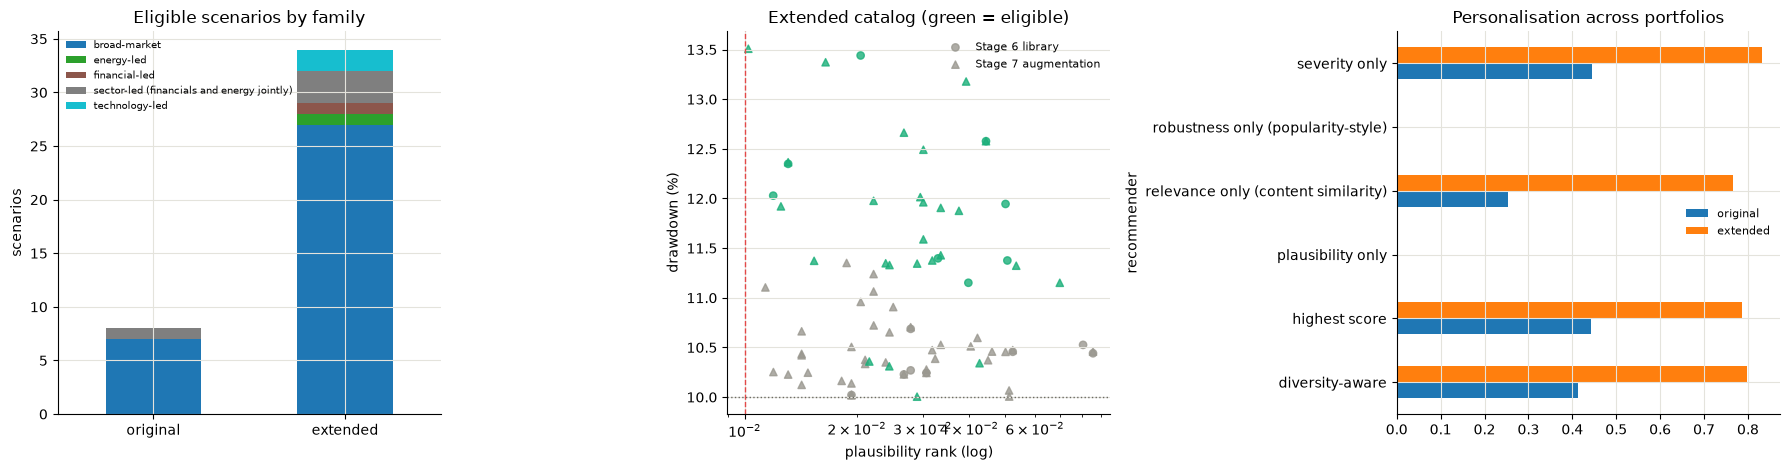

In [16]:
# 13c. Visualisations
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
fam_counts = pd.DataFrame({"original": features.loc[features["eligible"], "family"].value_counts(),
                           "extended": XF.loc[XF["eligible"], "family"].value_counts()}).fillna(0).astype(int)
fam_counts.T.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10", rot=0)
axes[0].set_title("Eligible scenarios by family"); axes[0].legend(frameon=False, fontsize=7); axes[0].set_ylabel("scenarios")
for origin, mk in (("Stage 6 library", "o"), ("Stage 7 augmentation", "^")):
    d = XF[XF["origin"] == origin]
    axes[1].scatter(d["rank"], d["deterministic_drawdown"] * 100, marker=mk, c=np.where(d["eligible"], "#1baf7a", "#9a9890"), s=28, label=origin, alpha=0.8)
axes[1].axvline(RCFG.q, color="#e34948", ls="--", lw=1); axes[1].axhline(dd_limit * 100, color="#6b6a63", ls=":", lw=1)
axes[1].set_xscale("log"); axes[1].set_xlabel("plausibility rank (log)"); axes[1].set_ylabel("drawdown (%)")
axes[1].set_title("Extended catalog (green = eligible)"); axes[1].legend(frameon=False, fontsize=8)
p = personal["personalisation (1 - mean Jaccard)"].unstack("catalog")[["original", "extended"]]
p.plot(kind="barh", ax=axes[2]); axes[2].set_title("Personalisation across portfolios"); axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [17]:
# 13d. Save the extension (separate file; the frozen v2 output is untouched) and checks
hash_after_ext = {name: tree_hash(paths) for name, paths in PROTECTED.items()}
ext_output = {
    "stage": 7, "schema_version": "stage7.ext1", "generated_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "provenance": {"library_path": str(LIBRARY_PATH.relative_to(PROJECT_ROOT)), "library_sha256": LIB_SHA,
                   "stage7_v2_path": str(OUT_PATH.relative_to(PROJECT_ROOT)), "stage7_v2_sha256": V2_SHA, "test_split_used": False,
                   "note": "extension only; Stage 8 tested the v2 catalog and shortlists, not this extended catalog"},
    "method": {"source_paths": "Stage 6 robust_action_path (16 scenarios)", "intensity_scales": list(SCALES),
               "timing": ["reversed days", "front-loaded", "back-loaded"], "factor_tilts": {k: list(v) for k, v in TILTS.items()},
               "near_duplicate_cut": NEAR_DUP_CUT, "cluster_cut": CLUSTER_CUT, "family_delta": FAMILY_DELTA, "p_valid_target": P_VALID_TARGET,
               "eligibility": dataclasses.asdict(RCFG)},
    "seeds": {"screening (selection)": [SCREEN_SEEDS.start, SCREEN_SEEDS.stop - 1], "reporting": [REPORT_SEEDS.start, REPORT_SEEDS.stop - 1],
              "independent": [FRESH_SEEDS.start, FRESH_SEEDS.stop - 1], "random shortlists (RNG only)": [RANDOM_SEEDS.start, RANDOM_SEEDS.stop - 1],
              "random portfolios (RNG only)": DIRICHLET_SEED, "anchors": "validation split"},
    "funnel": funnel, "catalog_sizes": catalog_sizes.to_dict(), "coverage": ext_gaps.to_dict("records"),
    "catalog": [{**ext_by_id[r.scenario_id], "eligible": bool(r.eligible), "ineligible_reason": r.ineligible_reason} for r in XF.itertuples()],
    "independent_evaluation": ext_fresh.reset_index().to_dict("records"),
    "comparison_default_portfolio": {"original": cmp_original.reset_index().to_dict("records"), "extended": cmp_extended.reset_index().to_dict("records")},
    "across_portfolios": personal.reset_index().to_dict("records"),
    "profile_shortlists_extended": {r: {p: lists["extended"][r][p] for p in PORTFOLIOS} for r in RECOMMENDERS},
    "runtime_seconds": {"robustness": robust_runtime, "independent_evaluation": ext_fresh_runtime, "across_portfolios": personal_runtime},
}
EXT_DIR.mkdir(parents=True, exist_ok=True)
if EXT_PATH.exists() and not EXT_OVERWRITE:
    raise FileExistsError(f"{EXT_PATH} exists; set EXT_OVERWRITE = True to replace it deliberately")
EXT_PATH.write_text(to_json(ext_output))

ext_checks = []
def xcheck(name, ok, detail=""):
    ext_checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})
xcheck("frozen Stage 4-6 results unchanged", hash_after_ext == HASH_BEFORE)
xcheck("frozen Stage 7 v2 output unchanged", library_fingerprint(OUT_PATH) == V2_SHA, V2_SHA[:12])
xcheck("all candidate paths within the action bound", all(np.abs(c["path"]).max() <= 1.0 for c in cands.values()))
xcheck("Stage 6 originals reproduced (deterministic rank and drawdown)", det_diff < 1e-9, f"max diff {det_diff:.1e}")
xcheck("Stage 6 originals reproduced (screening P(valid) and status)", originals_reproduced)
xcheck("section 4 impacts reproduced for every profile", impact_repro < 1e-9, f"max diff {impact_repro:.1e}")
xcheck("every extended scenario eligible only under the unchanged Stage 7 rule", bool((XF.loc[XF["eligible"], "status"] == "validated").all()
       and (XF.loc[XF["eligible"], "rank"] >= RCFG.q).all() and (XF.loc[XF["eligible"], "screening_p_valid"] >= RCFG.min_screening_p_valid).all()))
xcheck("all shortlisted scenarios eligible (both catalogs, all portfolios)", all(
    set(ids) <= set((features if cat == "original" else XF).query("eligible")["scenario_id"]) for cat in lists for r in lists[cat] for ids in lists[cat][r].values()))
xcheck("independent evaluation: 500 fresh episodes for every eligible extended scenario", set(ext_fresh.index) == set(XE["scenario_id"]) and (ext_fresh["episodes"] == 500).all())
xcheck("independent seeds disjoint from selection seeds", seeds_independent and not set(FRESH_SEEDS) & (set(SCREEN_SEEDS) | set(REPORT_SEEDS)))
xcheck("original-catalog shortlists equal the frozen v2 shortlists", cmp_original.loc["highest score", "shortlist"] == ", ".join(top_ids)
       and cmp_original.loc["diversity-aware", "shortlist"] == ", ".join(div_ids))
xcheck("anchors: validation split only (no test data)", eval_env.market_states.index.max() <= pd.Timestamp(CFG.data.splits.as_dict()["validation"][1])
       and det_env.market_states.index.min() >= pd.Timestamp(CFG.data.splits.as_dict()["validation"][0]))
ext_checks_df = pd.DataFrame(ext_checks)
display(ext_checks_df.style.hide(axis="index").map(lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))
assert (ext_checks_df["result"] == "PASS").all()
print(f"{len(ext_checks_df)}/{len(ext_checks_df)} extension checks PASS | wrote {EXT_PATH.relative_to(PROJECT_ROOT)}")
print(f"Catalog: {len(features)} -> {len(XF)} scenarios; eligible {int(features['eligible'].sum())} -> {int(XF['eligible'].sum())}; "
      f"eligible families {features.loc[features['eligible'], 'family'].nunique()} -> {XF.loc[XF['eligible'], 'family'].nunique()}")

check,result,detail
frozen Stage 4-6 results unchanged,PASS,
frozen Stage 7 v2 output unchanged,PASS,045dfb911fa1
all candidate paths within the action bound,PASS,
Stage 6 originals reproduced (deterministic rank and drawdown),PASS,max diff 0.0e+00
Stage 6 originals reproduced (screening P(valid) and status),PASS,
section 4 impacts reproduced for every profile,PASS,max diff 0.0e+00
every extended scenario eligible only under the unchanged Stage 7 rule,PASS,
"all shortlisted scenarios eligible (both catalogs, all portfolios)",PASS,
independent evaluation: 500 fresh episodes for every eligible extended scenario,PASS,
independent seeds disjoint from selection seeds,PASS,


12/12 extension checks PASS | wrote results/stage7_extension/extended_catalog.json
Catalog: 16 -> 82 scenarios; eligible 8 -> 34; eligible families 2 -> 5


## 14. Limitations of the extension
- The new scenarios are **transformations of paths the Stage 5 searches discovered** (rescaled, re-timed or factor-tilted). They are not new RL discoveries.
- The tilted paths use continuous factor shocks outside the nine grouped actions, so no Stage 5 discrete agent could produce them.
- Screening selects on seeds 10000–10199, as Stage 6 did. The robustness score uses reporting seeds 20000–20499, so it is in-sample, as in sections 5–7. Only the independent columns (30000–30499) are free of selection.
- Variants of the same parent stay correlated even after the near-duplicate merge. The diversity-aware recommender and the cluster count expose this; they do not remove it.
- **Stage 8 tested the v2 catalog and shortlists only.** The extended catalog has no held-out test result. The 2024–2025 split is consumed and must not be used to evaluate it.
- There are still no ground-truth relevance labels, so ranking-accuracy metrics (NDCG, hit rate) are not reported.